# Carbon-Aware Spatial Workload Shifting

**Purpose.** Benchmark regional electricity carbon-intensity signals and optimize the placement (and, optionally, execution time) of cloud workloads across geographical regions.

The notebook implements:

1. Regional dataset ingestion, UTC normalization, validation and EDA.
2. A local-immediate baseline and a workload model with release times, deadlines, durations, power demand and transferred data.
3. A greedy joint region/time heuristic.
4. A binary MILP solved with `scipy.optimize.milp` for spatial-only, temporal-only and joint spatio-temporal scheduling.
5. Carbon, SLA, migration, capacity and network KPIs, with diagnostic plots.

**Important interpretation.** The carbon-intensity column in the supplied files is an estimated, generation-mix-weighted lifecycle intensity. It is not automatically a consumption-based or marginal-emissions signal. The network-energy parameters and data-center capacities are experimental inputs and must be calibrated or varied in sensitivity experiments. The notebook does not infer these values from the generation files.

## Model assumptions

- One slot is 15 minutes (`DELTA_HOURS = 0.25`).
- A job is non-preemptive and draws constant power during its execution.
- A job is assigned to exactly one region and one start slot.
- Remote data transfer is represented as occurring in the job's start slot. Its bandwidth is measured in GB per 15-minute slot. This is a tractable first model; a multi-slot transfer model is needed when migration time is material.
- Regional capacity is expressed in kW. Link capacity is expressed in GB per slot.
- Network emissions are estimated using network kWh/GB multiplied by the mean of origin and destination carbon intensity at transfer time. Replace this endpoint approximation with route-specific network emissions when such data are available.

## Required input files

Place the regional CSV files in the notebook's working directory and add their paths to `DATA_FILES`. The first entry is configured for the uploaded DE-LU file. Add the other regions using the same structure.

In [9]:
# Optional dependency installation (run only if a package is missing)
# %pip install -U pandas numpy matplotlib scipy

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# -----------------------------
# User configuration
# -----------------------------
DATA_FILES = {
    "DE-LU": "data/DE-LU_generation_with_estimated_carbon_intensity.csv",
    "FR": "data/FR_generation_with_estimated_carbon_intensity.csv",
    # "PL": "PL_generation_with_estimated_carbon_intensity.csv",
    # "SE": "SE_generation_with_estimated_carbon_intensity.csv",
    # "NO": "NO_generation_with_estimated_carbon_intensity.csv",
    # "FI": "FI_generation_with_estimated_carbon_intensity.csv",
}

# Optional measured workload CSV. Required columns are documented in Section 4.
# Leave as None to generate a reproducible synthetic workload.
JOBS_FILE = None  # e.g. "jobs.csv"

MTU_COL = "MTU (CET/CEST)"
CI_COL = "Estimated carbon intensity (gCO2eq/kWh)"
DELTA_HOURS = 0.25
SOURCE_TIMEZONE = "Europe/Brussels"  # MTU labels are CET/CEST; convert all regions to UTC.

# A value such as "2026-09-01 00:00:00+00:00" pins the window.
# None selects the first continuous window with valid CI in every configured region.
PREFERRED_START_UTC = None
HORIZON_DAYS = 2

# Synthetic workload is a replaceable experiment input, not observed cloud telemetry.
N_SYNTHETIC_JOBS = 36
WORKLOAD_RANDOM_SEED = 42
DEFAULT_REGION_CAPACITY_KW = 15.0
DEFAULT_NETWORK_KWH_PER_GB = 0.01  # illustrative placeholder; calibrate or run sensitivity analysis
DEFAULT_LINK_CAPACITY_GB_PER_SLOT = 100.0  # illustrative placeholder
NETWORK_ENDPOINT_WEIGHT = 0.5  # 0.5 = equal weighting of origin and destination grid CI
MILP_TIME_LIMIT_SECONDS = 60

print("Configured regions:", list(DATA_FILES))


Configured regions: ['DE-LU', 'FR']


## 1. Load and normalize the regional carbon-intensity series

The source file contains one row per production type and interval. Carbon intensity is repeated across production-type rows, so the time series must be reduced to one observation per interval. The parser reads the interval's **start** timestamp, honors explicit `(CET)` and `(CEST)` labels, localizes untagged times to the CET/CEST time zone, and converts them to UTC.

UTC is the comparison key across regions. If an untagged timestamp is ambiguous or nonexistent, it is left invalid rather than guessed.

In [10]:
def parse_mtu_start_utc(mtu: pd.Series, source_timezone: str = SOURCE_TIMEZONE) -> pd.Series:
    """Parse the left endpoint of ENTSO-E-style MTU strings into UTC timestamps."""
    text = mtu.astype("string")
    extracted = text.str.extract(
        r"^\s*(?P<dt>\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2})(?:\s*\((?P<zone>CET|CEST)\))?"
    )
    naive = pd.to_datetime(extracted["dt"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
    out = pd.Series(pd.NaT, index=mtu.index, dtype="datetime64[ns, UTC]")

    for zone, offset_hours in (("CET", 1), ("CEST", 2)):
        mask = extracted["zone"].eq(zone)
        if mask.any():
            out.loc[mask] = (naive.loc[mask] - pd.Timedelta(hours=offset_hours)).dt.tz_localize("UTC")

    untagged = extracted["zone"].isna() & naive.notna()
    if untagged.any():
        localized = naive.loc[untagged].dt.tz_localize(
            source_timezone, ambiguous="NaT", nonexistent="NaT"
        )
        out.loc[untagged] = localized.dt.tz_convert("UTC")
    return out


def load_region_ci(region: str, path: str | Path) -> tuple[pd.Series, dict]:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Missing file for {region}: {path.resolve()}. Put the CSV beside the notebook or update DATA_FILES."
        )

    raw = pd.read_csv(path)
    missing_cols = [c for c in (MTU_COL, CI_COL) if c not in raw.columns]
    if missing_cols:
        raise ValueError(f"{path.name} is missing required columns: {missing_cols}")

    ts = parse_mtu_start_utc(raw[MTU_COL])
    ci = pd.to_numeric(raw[CI_COL], errors="coerce")
    valid_ts = ts.notna()
    if not valid_ts.all():
        examples = raw.loc[~valid_ts, MTU_COL].drop_duplicates().head(5).tolist()
        warnings.warn(f"{region}: {int((~valid_ts).sum())} source rows have unparseable/ambiguous timestamps. Examples: {examples}")

    work = pd.DataFrame({"timestamp_utc": ts.loc[valid_ts], "ci": ci.loc[valid_ts]})
    # Carbon intensity should be identical across production-type rows for one interval.
    distinct = work.groupby("timestamp_utc")["ci"].nunique(dropna=True)
    inconsistent = int((distinct > 1).sum())
    if inconsistent:
        warnings.warn(f"{region}: {inconsistent} intervals contain inconsistent repeated CI values; using the median.")
        series = work.groupby("timestamp_utc")["ci"].median()
    else:
        series = work.groupby("timestamp_utc")["ci"].first()

    series = series.sort_index().astype(float)
    series.name = region
    diagnostics = {
        "region": region,
        "file": path.name,
        "raw_rows": len(raw),
        "unique_intervals": int(series.shape[0]),
        "valid_ci_intervals": int(series.notna().sum()),
        "coverage_pct": float(series.notna().mean() * 100),
        "first_utc": series.index.min(),
        "last_utc": series.index.max(),
        "inconsistent_intervals": inconsistent,
        "unparsed_rows": int((~valid_ts).sum()),
    }
    return series, diagnostics


region_series = {}
load_diagnostics = []
for region, file_path in DATA_FILES.items():
    series, diag = load_region_ci(region, file_path)
    region_series[region] = series
    load_diagnostics.append(diag)

ci_raw = pd.concat(region_series.values(), axis=1).sort_index()
ci_raw.index.name = "timestamp_utc"
load_report = pd.DataFrame(load_diagnostics).set_index("region")
display(load_report)
print("Raw aligned dataframe shape:", ci_raw.shape)
display(ci_raw.head())


,file,raw_rows,unique_intervals,valid_ci_intervals,coverage_pct,first_utc,last_utc,inconsistent_intervals,unparsed_rows
region,,,,,,,,,
DE-LU,DE-LU_generation_with_estimated_carbon_intensi...,735840,35040,27130,77.425799,2025-12-31 23:00:00+00:00,2026-12-31 22:45:00+00:00,0,0
FR,FR_generation_with_estimated_carbon_intensity.csv,735840,35040,27025,77.126142,2025-12-31 23:00:00+00:00,2026-12-31 22:45:00+00:00,0,0


Raw aligned dataframe shape: (35040, 2)


,DE-LU,FR
timestamp_utc,,
2025-12-31 23:00:00+00:00,225.169152,39.762423
2025-12-31 23:15:00+00:00,216.161499,40.478146
2025-12-31 23:30:00+00:00,208.464811,37.857310
2025-12-31 23:45:00+00:00,203.032002,37.857310
2026-01-01 00:00:00+00:00,194.781919,NaN


## 2. Data quality, coverage and regional benchmarking

Do not forward-fill carbon intensity across long gaps. A zero-generation / null-intensity interval is not evidence of zero emissions. For cross-region correlations and optimization, use pairwise-complete observations or a common complete window, and report the resulting coverage.

Recommended EDA outputs:

- Mean, standard deviation, coefficient of variation and quantiles by region.
- Pearson and Spearman correlations on common observations.
- Diurnal and weekly profiles, with attention to seasonal differences.
- Pairwise lead/lag correlations on de-seasonalized series if regional cycles appear offset.
- The fraction of intervals in which each region is the cleanest.
- The theoretical clean-region opportunity: mean regional-average CI versus the per-interval minimum CI. This is an unconstrained upper bound, not an achievable saving estimate.

,valid_intervals,coverage_pct,mean_g_per_kwh,std_g_per_kwh,cv_pct,p05,median,p95,minimum,maximum
region,,,,,,,,,,
FR,27025,77.13,36.49,13.60,37.27,21.35,31.64,64.90,19.34,82.46
DE-LU,27130,77.43,306.67,126.53,41.26,114.85,313.74,508.74,79.73,598.04


,region,month_utc,valid_slots,expected_slots,coverage_pct,mean_ci_g_per_kwh
0,DE-LU,2026-01,2976,2976,100.00,354.40
1,DE-LU,2026-02,2688,2688,100.00,342.30
2,DE-LU,2026-03,2972,2972,100.00,336.64
3,DE-LU,2026-04,2880,2880,100.00,280.58
4,DE-LU,2026-05,2976,2976,100.00,292.93
5,DE-LU,2026-06,2880,2880,100.00,274.71
6,DE-LU,2026-07,2976,2976,100.00,271.14
7,DE-LU,2026-08,2976,2976,100.00,285.97
8,DE-LU,2026-09,2880,2880,100.00,307.40
9,DE-LU,2026-10,926,2980,31.07,356.86


Pearson correlation (pairwise complete observations):


,DE-LU,FR
DE-LU,1.000,0.376
FR,0.376,1.000


Spearman correlation:


,DE-LU,FR
DE-LU,1.000,0.318
FR,0.318,1.000


Correlation of hour-of-week anomalies:


,DE-LU,FR
DE-LU,1.000,0.407
FR,0.407,1.000


C:\Users\user\AppData\Local\Temp\ipykernel_14044\3143455956.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


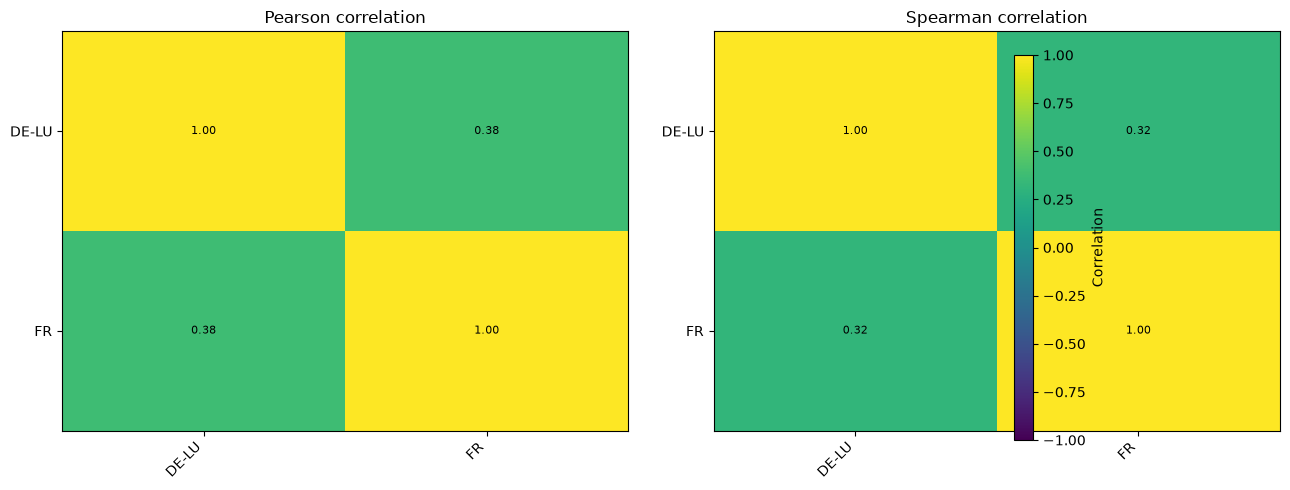

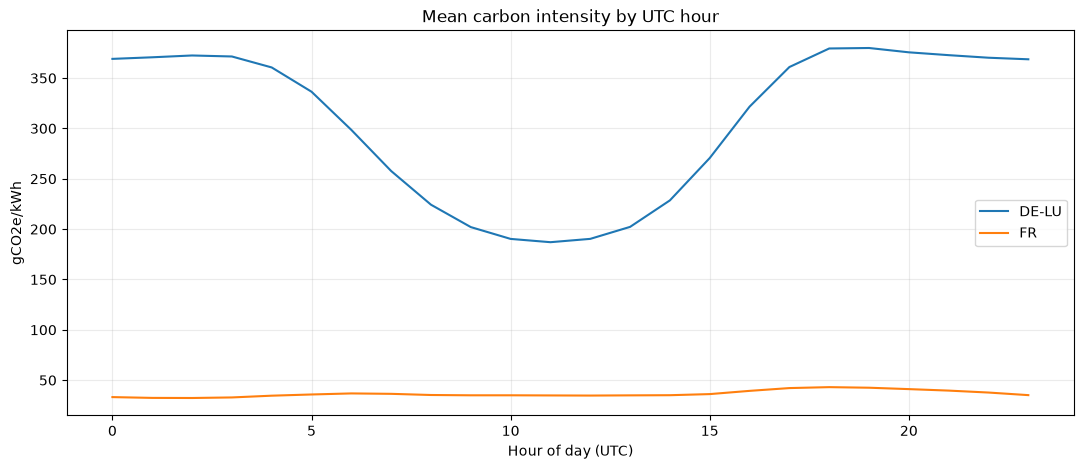

Common valid intervals: 27,025
Unconstrained mean CI gap: 135.38 gCO2e/kWh
Unconstrained spatial opportunity ceiling: 78.77%
Share of common intervals in which each region is cleanest:


,cleanest_share_pct
FR,100.0
DE-LU,0.0


In [11]:
# Use a regular UTC grid so absent intervals are explicit NaNs.
full_index = pd.date_range(ci_raw.index.min(), ci_raw.index.max(), freq="15min", tz="UTC")
ci = ci_raw.reindex(full_index)
ci.index.name = "timestamp_utc"
regions = list(ci.columns)

stats_rows = []
for region in regions:
    s = ci[region].dropna()
    stats_rows.append({
        "region": region,
        "valid_intervals": len(s),
        "coverage_pct": 100 * ci[region].notna().mean(),
        "mean_g_per_kwh": s.mean(),
        "std_g_per_kwh": s.std(),
        "cv_pct": 100 * s.std() / s.mean() if s.mean() else np.nan,
        "p05": s.quantile(0.05),
        "median": s.median(),
        "p95": s.quantile(0.95),
        "minimum": s.min(),
        "maximum": s.max(),
    })
regional_stats = pd.DataFrame(stats_rows).set_index("region").sort_values("mean_g_per_kwh")
display(regional_stats.round(2))

# Monthly validity is important: the source file may contain rows beyond its last valid observation.
monthly_rows = []
ci_local = ci.copy()
ci_local.index = ci_local.index.tz_convert(SOURCE_TIMEZONE)
for region in regions:
    grouped = ci_local[region].resample("MS")
    for month, values in grouped:
        monthly_rows.append({
            "region": region,
            "month_utc": month.strftime("%Y-%m"),
            "valid_slots": int(values.notna().sum()),
            "expected_slots": int(len(values)),
            "coverage_pct": 100 * float(values.notna().mean()) if len(values) else np.nan,
            "mean_ci_g_per_kwh": float(values.mean()) if values.notna().any() else np.nan,
        })
monthly_coverage = pd.DataFrame(monthly_rows)
display(monthly_coverage.round(2))

pearson_corr = ci.corr(method="pearson", min_periods=96)
spearman_corr = ci.corr(method="spearman", min_periods=96)
print("Pearson correlation (pairwise complete observations):")
display(pearson_corr.round(3))
print("Spearman correlation:")
display(spearman_corr.round(3))

# Remove the average hour-of-week profile before checking whether regional deviations co-move.
hour_of_week = ci.index.dayofweek * 24 + ci.index.hour
hour_of_week_profile = ci.groupby(hour_of_week).transform("mean")
ci_anomalies = ci - hour_of_week_profile
anomaly_corr = ci_anomalies.corr(method="pearson", min_periods=96)
print("Correlation of hour-of-week anomalies:")
display(anomaly_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, mat, title in [
    (axes[0], pearson_corr, "Pearson correlation"),
    (axes[1], spearman_corr, "Spearman correlation"),
]:
    im = ax.imshow(mat, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(regions)), regions, rotation=45, ha="right")
    ax.set_yticks(range(len(regions)), regions)
    ax.set_title(title)
    for i in range(len(regions)):
        for j in range(len(regions)):
            if pd.notna(mat.iloc[i, j]):
                ax.text(j, i, f"{mat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes, label="Correlation")
fig.tight_layout()
plt.show()

# Regional average 15-minute profile by UTC hour.
hourly_profile = ci.groupby(ci.index.hour).mean()
ax = hourly_profile.plot(figsize=(13, 5), linewidth=1.5)
ax.set_title("Mean carbon intensity by UTC hour")
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("gCO2e/kWh")
ax.grid(alpha=0.25)
plt.show()

# Spatial opportunity ceiling, calculated only where every configured region has a valid observation.
common_ci = ci.dropna(how="any")
if len(regions) >= 2 and not common_ci.empty:
    cleanest = common_ci.min(axis=1)
    cross_region_mean = common_ci.mean(axis=1)
    theoretical_opportunity_g_per_kwh = float((cross_region_mean - cleanest).mean())
    theoretical_opportunity_pct = float(
        100 * (cross_region_mean.mean() - cleanest.mean()) / cross_region_mean.mean()
    )
    cleanest_region_share = common_ci.eq(cleanest, axis=0).mean().sort_values(ascending=False)
    print(f"Common valid intervals: {len(common_ci):,}")
    print(f"Unconstrained mean CI gap: {theoretical_opportunity_g_per_kwh:.2f} gCO2e/kWh")
    print(f"Unconstrained spatial opportunity ceiling: {theoretical_opportunity_pct:.2f}%")
    print("Share of common intervals in which each region is cleanest:")
    display((100 * cleanest_region_share).round(1).rename("cleanest_share_pct").to_frame())
else:
    print("Cross-region opportunity metrics require at least two regions with overlapping valid data.")


### Complementary regional cycles and lag analysis

A low correlation is not, by itself, proof of useful complementarity. Check whether the low-intensity periods actually overlap with workload flexibility. For each region pair, compute lead/lag correlations on the common time series. A positive lag means the second series is shifted forward relative to the first under the convention used below. For publication-quality analysis, also repeat this on anomalies after removing hour-of-week and seasonal means.

Lag correlation: DE-LU vs FR (15-minute slots)


,correlation
lag_slots,
-8,0.369984
-7,0.372368
-6,0.374571
-5,0.376452
-4,0.377871
-3,0.378698
-2,0.378783
-1,0.377988
0,0.376217


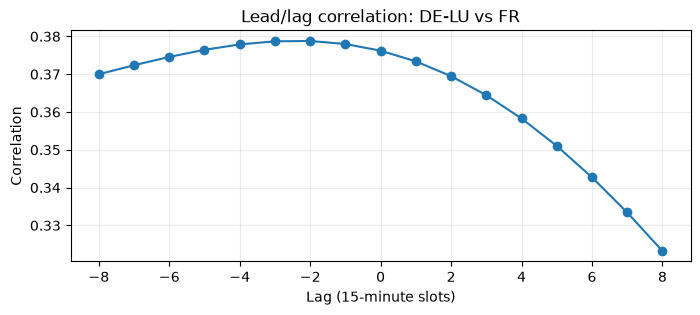

In [12]:
def lagged_correlation(a: pd.Series, b: pd.Series, max_lag_slots: int = 8) -> pd.Series:
    """corr(a[t], b[t+lag]); positive lag means b is evaluated later."""
    joined = pd.concat([a, b], axis=1).dropna()
    x, y = joined.iloc[:, 0], joined.iloc[:, 1]
    values = {}
    for lag in range(-max_lag_slots, max_lag_slots + 1):
        values[lag] = x.corr(y.shift(-lag))
    return pd.Series(values, name="correlation")

if len(regions) >= 2:
    pair = (regions[0], regions[1])
    lag_corr = lagged_correlation(ci[pair[0]], ci[pair[1]], max_lag_slots=8)
    print(f"Lag correlation: {pair[0]} vs {pair[1]} (15-minute slots)")
    display(lag_corr.rename_axis("lag_slots").to_frame())
    ax = lag_corr.plot(marker="o", figsize=(8, 3))
    ax.set_xlabel("Lag (15-minute slots)")
    ax.set_ylabel("Correlation")
    ax.set_title(f"Lead/lag correlation: {pair[0]} vs {pair[1]}")
    ax.grid(alpha=0.25)
    plt.show()


## 3. Select a common experimental horizon

The optimization requires valid CI observations in every region for every interval in the modeled horizon. The selector below finds a continuous common window, or verifies a user-specified UTC start. For a more rigorous study, repeat the experiment over several non-overlapping windows (e.g., winter, spring, summer and autumn) and summarize results across windows.

In [13]:
def select_common_window(
    carbon: pd.DataFrame,
    horizon_days: int,
    preferred_start_utc: str | None = None,
    slot_minutes: int = 15,
) -> tuple[pd.DataFrame, pd.Timestamp]:
    n_slots = int(horizon_days * 24 * 60 / slot_minutes)
    if preferred_start_utc is not None:
        start = pd.Timestamp(preferred_start_utc)
        if start.tzinfo is None:
            start = start.tz_localize("UTC")
        else:
            start = start.tz_convert("UTC")
        target_index = pd.date_range(start, periods=n_slots, freq=f"{slot_minutes}min", tz="UTC")
        window = carbon.reindex(target_index)
        if window.isna().any().any():
            bad = window.isna().sum().to_dict()
            raise ValueError(f"The requested window is not complete across regions. Missing counts: {bad}")
        return window, start

    regular_index = pd.date_range(carbon.index.min(), carbon.index.max(), freq=f"{slot_minutes}min", tz="UTC")
    aligned = carbon.reindex(regular_index)
    valid = aligned.notna().all(axis=1).to_numpy()
    if n_slots > len(valid):
        raise ValueError("Requested horizon is longer than the available dataset overlap.")
    # Find first run of consecutive common-valid intervals.
    run = 0
    for i, ok in enumerate(valid):
        run = run + 1 if ok else 0
        if run >= n_slots:
            start_i = i - n_slots + 1
            start = regular_index[start_i]
            return aligned.iloc[start_i : start_i + n_slots].copy(), start
    raise ValueError(
        f"No continuous {horizon_days}-day interval has valid CI in all regions. "
        "Reduce HORIZON_DAYS, add/repair data, or select a different observation period."
    )


try:
    carbon_window, window_start = select_common_window(ci, HORIZON_DAYS, PREFERRED_START_UTC)
    horizon_slots = len(carbon_window)
    print("Selected UTC horizon:", carbon_window.index[0], "to", carbon_window.index[-1])
    print("Regions:", regions, "| slots:", horizon_slots)
    display(carbon_window.head())
except ValueError as exc:
    carbon_window = None
    horizon_slots = 0
    print("Horizon selection not completed:", exc)


Selected UTC horizon: 2026-01-02 01:45:00+00:00 to 2026-01-04 01:30:00+00:00
Regions: ['DE-LU', 'FR'] | slots: 192


,DE-LU,FR
2026-01-02 01:45:00+00:00,165.116036,27.905920
2026-01-02 02:00:00+00:00,165.426610,31.383427
2026-01-02 02:15:00+00:00,165.610110,31.592427
2026-01-02 02:30:00+00:00,166.678422,31.405635
2026-01-02 02:45:00+00:00,168.417934,31.345747


## 4. Define the workload and infrastructure inputs

The generation CSVs provide the **regional carbon signal**, not cloud job telemetry. The following jobs are therefore synthetic examples that make the optimizer executable. Replace them with measured or trace-derived workloads when available.

Each job has:

- `home_region`: its unshifted/local region.
- `release_slot`: earliest permitted start, relative to the selected horizon.
- `deadline_slot`: exclusive completion deadline.
- `duration_slots`: non-preemptive execution length.
- `power_kw`: constant IT power draw during execution.
- `transfer_gb`: total WAN data volume for a remote execution (input + output/checkpoints that must cross the WAN).

Infrastructure inputs are separate from the carbon dataset: `capacity_kw[r,t]`, `network_kwh_per_gb[o,r]` and `bandwidth_gb_per_slot[o,r]`. The defaults below are illustrative only.

In [14]:
def make_synthetic_jobs(
    region_names: list[str],
    n_jobs: int,
    n_slots: int,
    seed: int = 42,
) -> pd.DataFrame:
    if len(region_names) == 0:
        raise ValueError("At least one region is required.")
    if n_slots < 16:
        raise ValueError("The horizon is too short for the default synthetic workload generator.")

    rng = np.random.default_rng(seed)
    rows = []
    max_duration = min(8, max(1, n_slots // 8))
    latest_release = max(1, n_slots - max_duration - 1)
    release_upper = max(1, min(n_slots // 2, 96, latest_release + 1))

    for j in range(n_jobs):
        duration = int(rng.choice([1, 2, 4, max_duration]))
        duration = min(duration, max_duration)
        release = int(rng.integers(0, release_upper))
        if release + duration >= n_slots:
            release = max(0, n_slots - duration - 1)
        slack = int(rng.integers(8, 33))
        deadline = min(n_slots, release + duration + slack)
        if deadline < release + duration:
            deadline = release + duration
        rows.append({
            "job_id": f"J{j+1:03d}",
            "home_region": str(rng.choice(region_names)),
            "release_slot": release,
            "deadline_slot": deadline,  # exclusive
            "duration_slots": duration,
            "power_kw": float(rng.uniform(0.5, 3.0)),
            "transfer_gb": float(rng.uniform(1.0, 15.0)),
        })

    jobs = pd.DataFrame(rows)
    return jobs.sort_values(["release_slot", "deadline_slot", "job_id"]).reset_index(drop=True)


if carbon_window is not None:
    if JOBS_FILE is None:
        jobs = make_synthetic_jobs(regions, N_SYNTHETIC_JOBS, horizon_slots, WORKLOAD_RANDOM_SEED)
        print("Using synthetic demonstration workload. Replace with a measured job trace for empirical claims.")
    else:
        jobs = pd.read_csv(JOBS_FILE)
        required_job_columns = [
            "job_id", "home_region", "release_slot", "deadline_slot",
            "duration_slots", "power_kw", "transfer_gb",
        ]
        missing_job_columns = [c for c in required_job_columns if c not in jobs.columns]
        if missing_job_columns:
            raise ValueError(f"{JOBS_FILE} is missing workload columns: {missing_job_columns}")
        jobs = jobs[required_job_columns].copy()
        jobs["release_slot"] = jobs["release_slot"].astype(int)
        jobs["deadline_slot"] = jobs["deadline_slot"].astype(int)
        jobs["duration_slots"] = jobs["duration_slots"].astype(int)
        for c in ["power_kw", "transfer_gb"]:
            jobs[c] = jobs[c].astype(float)
        if not set(jobs["home_region"]).issubset(set(regions)):
            raise ValueError("Every home_region in the jobs file must match a region in DATA_FILES.")
        if (jobs["release_slot"] < 0).any() or (jobs["deadline_slot"] > horizon_slots).any():
            raise ValueError("Job release/deadline slots must fall inside the selected horizon.")
        if (jobs["duration_slots"] <= 0).any() or (jobs["power_kw"] <= 0).any() or (jobs["transfer_gb"] < 0).any():
            raise ValueError("Jobs require positive duration and power, and non-negative transfer_gb.")
        if (jobs["release_slot"] + jobs["duration_slots"] > jobs["deadline_slot"]).any():
            raise ValueError("Every job must have at least one feasible start: release + duration <= deadline.")
        jobs = jobs.reset_index(drop=True)

n_regions = len(regions)

# Regional computing capacity (kW)
capacity_kw = pd.DataFrame(
    np.full(
        (n_regions, horizon_slots),
        DEFAULT_REGION_CAPACITY_KW,
        dtype=float
    ),
    index=regions,
    columns=range(horizon_slots),
)

# Network energy consumption (kWh/GB)
network_values = np.full(
    (n_regions, n_regions),
    DEFAULT_NETWORK_KWH_PER_GB,
    dtype=float
)

# No network transfer overhead for execution within the home region
np.fill_diagonal(network_values, 0.0)

network_kwh_per_gb = pd.DataFrame(
    network_values,
    index=regions,
    columns=regions,
)

# Network bandwidth capacity (GB/slot)
bandwidth_values = np.full(
    (n_regions, n_regions),
    DEFAULT_LINK_CAPACITY_GB_PER_SLOT,
    dtype=float
)

# Local execution does not consume WAN bandwidth
np.fill_diagonal(bandwidth_values, np.inf)

bandwidth_gb_per_slot = pd.DataFrame(
    bandwidth_values,
    index=regions,
    columns=regions,
)

display(jobs.head(10))

print("Job count:", len(jobs))

print(
    "Total nominal compute energy (kWh):",
    round(
        (jobs.power_kw * jobs.duration_slots * DELTA_HOURS).sum(),
        3
    )
)

print("Capacity and network matrices initialized successfully.")


Using synthetic demonstration workload. Replace with a measured job trace for empirical claims.


,job_id,home_region,release_slot,deadline_slot,duration_slots,power_kw,transfer_gb
0,J022,DE-LU,2,14,2,2.305898,7.466281
1,J018,DE-LU,2,22,4,1.036462,6.719401
2,J032,DE-LU,3,23,8,1.324653,3.023339
3,J033,FR,9,25,4,0.926482,13.951682
4,J028,FR,9,29,1,1.639441,3.833087
5,J002,FR,9,31,1,2.402849,12.004900
6,J010,DE-LU,12,39,2,1.067273,10.377396
7,J003,DE-LU,12,44,4,1.426995,13.974710
8,J008,FR,14,44,4,2.361905,14.545136
9,J023,FR,15,49,4,0.880780,10.748485


Job count: 36
Total nominal compute energy (kWh): 56.123
Capacity and network matrices initialized successfully.


## 5. Mathematical optimization model

Let jobs be indexed by \(j\), regions by \(r\), and slots by \(t\). A binary variable \(x_{jrs}\) equals one if job \(j\) is assigned to region \(r\) and starts in slot \(s\).

**Objective (grams CO₂e):**

\[
\min_x \sum_{j,r,s} x_{jrs}\left[
\underbrace{p_j\Delta h\sum_{k=0}^{d_j-1} CI_{r,s+k}}_{\text{compute emissions}}
+\underbrace{v_j\eta_{h_jr}\left(\alpha CI_{h_j,s}+(1-\alpha)CI_{r,s}\right)}_{\text{network-transfer emissions}}
\right].
\]

Here, \(p_j\) is job power in kW, \(d_j\) is duration in slots, \(v_j\) is transferred GB, \(\eta_{or}\) is network energy in kWh/GB, and \(CI\) is in gCO₂e/kWh. The endpoint-weight parameter \(\alpha\) defaults to 0.5.

**Exactly one assignment and SLA window:**

\[
\sum_{r}\sum_{s\in S_j}x_{jrs}=1,\qquad
S_j=\{s:a_j\le s,\ s+d_j\le b_j\}.
\]

**Regional compute capacity:**

\[
\sum_{j,r,s:\,s\le t<s+d_j}p_jx_{jrs}\le C_{rt}\quad\forall r,t.
\]

**Directed-link bandwidth (one-slot transfer approximation):**

\[
\sum_{j:h_j=o}v_jx_{jrt}\le B_{ort}\quad\forall o,r,t.
\]

The workload-allocation matrix is induced by the solution:

\[
W_{rt}=\sum_{j,s:\,s\le t<s+d_j}p_jx_{jrs}.
\]

The MILP below is optimal for this finite-horizon, deterministic, linear model if the solver reports an optimal status. Spatial-only scheduling fixes \(s=a_j\); temporal-only scheduling fixes \(r=h_j\); joint scheduling optimizes both. The model is not a full packet-level network-routing model.

In [15]:
def enumerate_candidates(
    jobs: pd.DataFrame,
    carbon: pd.DataFrame,
    capacity_kw: pd.DataFrame,
    network_kwh_per_gb: pd.DataFrame,
    allow_spatial: bool = True,
    allow_temporal: bool = True,
    endpoint_weight: float = NETWORK_ENDPOINT_WEIGHT,
) -> list[dict]:
    """Generate feasible job-region-start variables and their carbon coefficients."""
    region_names = list(carbon.columns)
    region_to_i = {r: i for i, r in enumerate(region_names)}
    H = carbon.shape[0]
    candidates = []

    jobs = jobs.reset_index(drop=True)
    for j_idx, job in jobs.iterrows():
        home = job["home_region"]
        if home not in region_to_i:
            raise ValueError(f"Unknown home_region {home!r} for job {job['job_id']}.")
        home_i = region_to_i[home]
        duration = int(job["duration_slots"])
        release = int(job["release_slot"])
        deadline = int(job["deadline_slot"])
        power = float(job["power_kw"])
        volume = float(job["transfer_gb"])

        region_options = region_names if allow_spatial else [home]
        if allow_temporal:
            starts = range(release, deadline - duration + 1)
        else:
            starts = [release]

        for dest in region_options:
            dest_i = region_to_i[dest]
            for start in starts:
                finish = start + duration
                if start < 0 or finish > H or finish > deadline:
                    continue
                ci_compute = carbon[dest].iloc[start:finish].to_numpy(dtype=float)
                if len(ci_compute) != duration or not np.isfinite(ci_compute).all():
                    continue
                compute_g = float(power * DELTA_HOURS * ci_compute.sum())

                network_kwh = 0.0
                network_g = 0.0
                if dest != home and volume > 0:
                    ci_home_transfer = float(carbon[home].iloc[start])
                    ci_dest_transfer = float(carbon[dest].iloc[start])
                    if not np.isfinite(ci_home_transfer) or not np.isfinite(ci_dest_transfer):
                        continue
                    network_kwh = volume * float(network_kwh_per_gb.loc[home, dest])
                    network_ci = endpoint_weight * ci_home_transfer + (1 - endpoint_weight) * ci_dest_transfer
                    network_g = network_kwh * network_ci

                candidates.append({
                    "job_idx": int(j_idx),
                    "job_id": job["job_id"],
                    "home_region": home,
                    "region": dest,
                    "home_i": home_i,
                    "region_i": dest_i,
                    "start_slot": int(start),
                    "finish_slot": int(finish),
                    "duration_slots": duration,
                    "power_kw": power,
                    "transfer_gb": volume if dest != home else 0.0,
                    "compute_emissions_g": compute_g,
                    "network_energy_kwh": network_kwh,
                    "network_emissions_g": network_g,
                    "objective_g": compute_g + network_g,
                })
    return candidates


def solve_spatial_milp(
    jobs: pd.DataFrame,
    carbon: pd.DataFrame,
    capacity_kw: pd.DataFrame,
    network_kwh_per_gb: pd.DataFrame,
    bandwidth_gb_per_slot: pd.DataFrame,
    allow_spatial: bool = True,
    allow_temporal: bool = True,
    time_limit_seconds: int = MILP_TIME_LIMIT_SECONDS,
) -> dict:
    """Solve a binary job-region-start MILP with SciPy/HiGHS."""
    candidates = enumerate_candidates(
        jobs, carbon, capacity_kw, network_kwh_per_gb,
        allow_spatial=allow_spatial,
        allow_temporal=allow_temporal,
    )
    if not candidates:
        raise RuntimeError("No feasible job-region-start variables were generated. Check data, deadlines and constraints.")

    J = len(jobs)
    R = len(carbon.columns)
    H = len(carbon)
    n_vars = len(candidates)
    n_capacity_rows = R * H
    n_link_rows = R * R * H
    n_rows = J + n_capacity_rows + n_link_rows

    row_idx, col_idx, values = [], [], []
    c = np.zeros(n_vars, dtype=float)
    for v_idx, var in enumerate(candidates):
        j = var["job_idx"]
        r = var["region_i"]
        start = var["start_slot"]
        c[v_idx] = var["objective_g"]

        # Exactly-one assignment row.
        row_idx.append(j); col_idx.append(v_idx); values.append(1.0)

        # Regional kW capacity rows for every occupied interval.
        for t in range(var["start_slot"], var["finish_slot"]):
            row = J + r * H + t
            row_idx.append(row); col_idx.append(v_idx); values.append(var["power_kw"])

        # Transfer volume is staged in the selected job start slot.
        if var["region"] != var["home_region"] and var["transfer_gb"] > 0:
            link_row = J + n_capacity_rows + (var["home_i"] * R + r) * H + start
            row_idx.append(link_row); col_idx.append(v_idx); values.append(var["transfer_gb"])

    A = coo_matrix((values, (row_idx, col_idx)), shape=(n_rows, n_vars)).tocsr()
    lower = np.full(n_rows, -np.inf, dtype=float)
    upper = np.full(n_rows, np.inf, dtype=float)
    lower[:J] = 1.0
    upper[:J] = 1.0
    upper[J : J + n_capacity_rows] = capacity_kw.loc[list(carbon.columns)].to_numpy(dtype=float).reshape(-1)

    link_capacity = np.zeros((R, R, H), dtype=float)
    for o_i, origin in enumerate(carbon.columns):
        for r_i, dest in enumerate(carbon.columns):
            link_capacity[o_i, r_i, :] = float(bandwidth_gb_per_slot.loc[origin, dest])
    upper[J + n_capacity_rows :] = link_capacity.reshape(-1)

    result = milp(
        c=c,
        integrality=np.ones(n_vars, dtype=int),
        bounds=Bounds(np.zeros(n_vars), np.ones(n_vars)),
        constraints=LinearConstraint(A, lower, upper),
        options={"time_limit": float(time_limit_seconds)},
    )
    if result.x is None:
        raise RuntimeError(f"MILP did not return a feasible incumbent. Solver status={result.status}; message={result.message}")

    chosen = [candidates[i] for i, value in enumerate(result.x) if value > 0.5]
    chosen_job_ids = {a["job_id"] for a in chosen}
    missing = sorted(set(jobs["job_id"]) - chosen_job_ids)
    if missing:
        raise RuntimeError(f"MILP incumbent is incomplete; jobs not assigned: {missing}")

    return {
        "assignments": [{"job_id": a["job_id"], "region": a["region"], "start_slot": a["start_slot"]} for a in chosen],
        "solver_result": result,
        "objective_g": float(result.fun),
        "status": int(result.status),
        "message": str(result.message),
        "candidate_count": n_vars,
    }


## 6. Greedy routing heuristic

The heuristic processes jobs in earliest-deadline-first order. For each job it enumerates feasible region/start combinations, rejects assignments that would exceed regional capacity or link bandwidth, and commits the lowest-emission remaining option.

This is a **myopic heuristic**, not a globally optimal scheduler: an early choice can consume capacity needed by a later job. The MILP is the exact benchmark for the stated deterministic model.

In [16]:
def greedy_spatial_minimum(
    jobs: pd.DataFrame,
    carbon: pd.DataFrame,
    capacity_kw: pd.DataFrame,
    network_kwh_per_gb: pd.DataFrame,
    bandwidth_gb_per_slot: pd.DataFrame,
    allow_spatial: bool = True,
    allow_temporal: bool = True,
) -> dict:
    candidates = enumerate_candidates(
        jobs, carbon, capacity_kw, network_kwh_per_gb,
        allow_spatial=allow_spatial,
        allow_temporal=allow_temporal,
    )
    by_job = {}
    for candidate in candidates:
        by_job.setdefault(candidate["job_id"], []).append(candidate)

    regions_local = list(carbon.columns)
    r_to_i = {r: i for i, r in enumerate(regions_local)}
    H = len(carbon)
    residual_capacity = capacity_kw.loc[regions_local].to_numpy(dtype=float).copy()
    link_used = np.zeros((len(regions_local), len(regions_local), H), dtype=float)
    link_cap = np.zeros_like(link_used)
    for oi, origin in enumerate(regions_local):
        for ri, dest in enumerate(regions_local):
            link_cap[oi, ri, :] = float(bandwidth_gb_per_slot.loc[origin, dest])

    ordered = jobs.sort_values(["deadline_slot", "release_slot", "job_id"])
    selected = []
    unassigned = []
    for _, job in ordered.iterrows():
        options = by_job.get(job["job_id"], [])
        feasible = []
        for option in options:
            ri = option["region_i"]
            s = option["start_slot"]
            e = option["finish_slot"]
            p = option["power_kw"]
            if np.any(residual_capacity[ri, s:e] + 1e-9 < p):
                continue
            oi = option["home_i"]
            if option["region"] != option["home_region"]:
                if link_used[oi, ri, s] + option["transfer_gb"] > link_cap[oi, ri, s] + 1e-9:
                    continue
            feasible.append(option)

        if not feasible:
            unassigned.append(job["job_id"])
            continue
        chosen = min(feasible, key=lambda z: (z["objective_g"], z["start_slot"], z["region"]))
        selected.append({"job_id": chosen["job_id"], "region": chosen["region"], "start_slot": chosen["start_slot"]})
        ri = chosen["region_i"]
        s, e = chosen["start_slot"], chosen["finish_slot"]
        residual_capacity[ri, s:e] -= chosen["power_kw"]
        if chosen["region"] != chosen["home_region"] and chosen["transfer_gb"] > 0:
            link_used[chosen["home_i"], ri, s] += chosen["transfer_gb"]

    return {"assignments": selected, "unassigned_jobs": unassigned}


## 7. Baseline and policy evaluation

The primary unshifted baseline assigns every job to its home region at its release slot. It measures the local, immediate execution footprint before spatial or temporal shifting. Because this accounting baseline does not queue jobs, its regional capacity overloads are reported separately.

For a fairer, capacity-feasible comparison, the notebook also solves a **local-only temporal** MILP (jobs remain in their home region but may move within their SLA window). Compare spatial-only and joint policies against both baselines when interpreting results.

In [17]:
def local_immediate_assignments(jobs: pd.DataFrame) -> list[dict]:
    return [
        {"job_id": row.job_id, "region": row.home_region, "start_slot": int(row.release_slot)}
        for row in jobs.itertuples(index=False)
    ]


def evaluate_schedule(
    assignments: list[dict],
    jobs: pd.DataFrame,
    carbon: pd.DataFrame,
    capacity_kw: pd.DataFrame,
    network_kwh_per_gb: pd.DataFrame,
    bandwidth_gb_per_slot: pd.DataFrame,
) -> dict:
    job_lookup = jobs.set_index("job_id")
    region_names = list(carbon.columns)
    r_to_i = {r: i for i, r in enumerate(region_names)}
    H = len(carbon)
    load = np.zeros((len(region_names), H), dtype=float)
    link_load = np.zeros((len(region_names), len(region_names), H), dtype=float)
    records = []
    assigned_ids = set()

    for assignment in assignments:
        job_id = assignment["job_id"]
        if job_id not in job_lookup.index:
            raise ValueError(f"Unknown job_id in schedule: {job_id}")
        job = job_lookup.loc[job_id]
        dest = assignment["region"]
        home = job["home_region"]
        start = int(assignment["start_slot"])
        duration = int(job["duration_slots"])
        finish = start + duration
        if dest not in r_to_i or home not in r_to_i:
            raise ValueError(f"Unknown region in assignment for {job_id}.")
        if start < 0 or finish > H:
            raise ValueError(f"Assignment for {job_id} falls outside the selected horizon.")
        ci_exec = carbon[dest].iloc[start:finish].to_numpy(dtype=float)
        if not np.isfinite(ci_exec).all():
            raise ValueError(f"Missing execution CI for {job_id} in {dest}.")

        power = float(job["power_kw"])
        energy_kwh = power * duration * DELTA_HOURS
        compute_g = float(power * DELTA_HOURS * ci_exec.sum())
        volume = float(job["transfer_gb"]) if dest != home else 0.0
        network_kwh = 0.0
        network_g = 0.0
        if volume > 0:
            ci_o = float(carbon[home].iloc[start])
            ci_d = float(carbon[dest].iloc[start])
            network_kwh = volume * float(network_kwh_per_gb.loc[home, dest])
            network_ci = NETWORK_ENDPOINT_WEIGHT * ci_o + (1 - NETWORK_ENDPOINT_WEIGHT) * ci_d
            network_g = network_kwh * network_ci
            link_load[r_to_i[home], r_to_i[dest], start] += volume

        load[r_to_i[dest], start:finish] += power
        assigned_ids.add(job_id)
        start_time = carbon.index[start]
        finish_time = carbon.index[finish] if finish < H else carbon.index[-1] + pd.Timedelta(minutes=15)
        records.append({
            "job_id": job_id,
            "home_region": home,
            "execution_region": dest,
            "start_slot": start,
            "finish_slot_exclusive": finish,
            "start_utc": start_time,
            "finish_utc": finish_time,
            "release_slot": int(job["release_slot"]),
            "deadline_slot_exclusive": int(job["deadline_slot"]),
            "duration_slots": duration,
            "power_kw": power,
            "compute_energy_kwh": energy_kwh,
            "compute_emissions_g": compute_g,
            "transfer_gb": volume,
            "network_energy_kwh": network_kwh,
            "network_emissions_g": network_g,
            "total_emissions_g": compute_g + network_g,
            "migrated": dest != home,
            "late": finish > int(job["deadline_slot"]),
        })

    schedule_df = pd.DataFrame(records)
    n_jobs = len(jobs)
    unassigned = sorted(set(jobs["job_id"]) - assigned_ids)
    if schedule_df.empty:
        total_compute_g = total_network_g = total_network_kwh = total_transfer_gb = 0.0
        migrated_jobs = 0
    else:
        total_compute_g = float(schedule_df["compute_emissions_g"].sum())
        total_network_g = float(schedule_df["network_emissions_g"].sum())
        total_network_kwh = float(schedule_df["network_energy_kwh"].sum())
        total_transfer_gb = float(schedule_df["transfer_gb"].sum())
        migrated_jobs = int(schedule_df["migrated"].sum())

    cap = capacity_kw.loc[region_names].to_numpy(dtype=float)
    capacity_over = load > cap + 1e-8
    bw_over = link_load > np.stack([
        np.full(H, float(bandwidth_gb_per_slot.loc[o, r]))
        for o in region_names for r in region_names
    ]).reshape(len(region_names), len(region_names), H) + 1e-8
    late_count = int(schedule_df["late"].sum()) if not schedule_df.empty else 0
    sla_violations = len(unassigned) + late_count
    total_capacity = float(cap.sum())
    utilization = 100 * float(load.sum()) / total_capacity if total_capacity > 0 else np.nan
    peak_utilization = float(np.max(np.divide(load, cap, out=np.zeros_like(load), where=cap > 0))) * 100

    metrics = {
        "jobs_total": n_jobs,
        "jobs_assigned": len(assigned_ids),
        "jobs_unassigned": len(unassigned),
        "sla_violation_rate_pct": 100 * sla_violations / n_jobs if n_jobs else np.nan,
        "compute_emissions_g": total_compute_g,
        "network_emissions_g": total_network_g,
        "total_emissions_g": total_compute_g + total_network_g,
        "total_emissions_kg": (total_compute_g + total_network_g) / 1000,
        "migrated_jobs": migrated_jobs,
        "migration_rate_pct": 100 * migrated_jobs / len(assigned_ids) if assigned_ids else 0.0,
        "total_transfer_gb": total_transfer_gb,
        "avg_transfer_gb_per_migrated_job": total_transfer_gb / migrated_jobs if migrated_jobs else 0.0,
        "network_energy_kwh": total_network_kwh,
        "avg_network_kwh_per_migrated_job": total_network_kwh / migrated_jobs if migrated_jobs else 0.0,
        "avg_network_g_per_migrated_job": total_network_g / migrated_jobs if migrated_jobs else 0.0,
        "capacity_utilization_pct": utilization,
        "peak_capacity_utilization_pct": peak_utilization,
        "capacity_violation_slots": int(capacity_over.sum()),
        "bandwidth_violation_slots": int(bw_over.sum()),
    }
    return {
        "schedule": schedule_df,
        "metrics": metrics,
        "load_kw": pd.DataFrame(load, index=region_names, columns=carbon.index),
        "link_load_gb": link_load,
        "unassigned_jobs": unassigned,
    }


## 8. Execute the policies

The experiment compares:

- `local_immediate`: all work stays local and starts at release.
- `greedy_joint`: myopic minimum-carbon region/start choice.
- `milp_spatial_only`: region optimized, start fixed at release.
- `milp_temporal_only`: home region fixed, start optimized.
- `milp_joint`: region and start optimized jointly.

All policies use the same workload, carbon window, capacity assumptions and transfer model.

In [18]:
policy_results = {}
if carbon_window is not None and len(regions) >= 2:
    baseline_assignments = local_immediate_assignments(jobs)
    policy_results["local_immediate"] = evaluate_schedule(
        baseline_assignments, jobs, carbon_window, capacity_kw,
        network_kwh_per_gb, bandwidth_gb_per_slot,
    )

    greedy_spatial = greedy_spatial_minimum(
        jobs, carbon_window, capacity_kw, network_kwh_per_gb,
        bandwidth_gb_per_slot, allow_spatial=True, allow_temporal=False,
    )
    policy_results["greedy_spatial_only"] = evaluate_schedule(
        greedy_spatial["assignments"], jobs, carbon_window, capacity_kw,
        network_kwh_per_gb, bandwidth_gb_per_slot,
    )
    policy_results["greedy_spatial_only"]["metrics"]["greedy_unassigned_jobs"] = len(greedy_spatial["unassigned_jobs"])

    greedy = greedy_spatial_minimum(
        jobs, carbon_window, capacity_kw, network_kwh_per_gb,
        bandwidth_gb_per_slot, allow_spatial=True, allow_temporal=True,
    )
    policy_results["greedy_joint"] = evaluate_schedule(
        greedy["assignments"], jobs, carbon_window, capacity_kw,
        network_kwh_per_gb, bandwidth_gb_per_slot,
    )
    policy_results["greedy_joint"]["metrics"]["greedy_unassigned_jobs"] = len(greedy["unassigned_jobs"])

    for name, spatial, temporal in [
        ("milp_spatial_only", True, False),
        ("milp_temporal_only", False, True),
        ("milp_joint", True, True),
    ]:
        try:
            solved = solve_spatial_milp(
                jobs, carbon_window, capacity_kw, network_kwh_per_gb,
                bandwidth_gb_per_slot, allow_spatial=spatial,
                allow_temporal=temporal,
            )
            evaluated = evaluate_schedule(
                solved["assignments"], jobs, carbon_window, capacity_kw,
                network_kwh_per_gb, bandwidth_gb_per_slot,
            )
            evaluated["solver"] = solved
            policy_results[name] = evaluated
            print(name, "| solver status:", solved["status"], "|", solved["message"], "| candidates:", solved["candidate_count"])
        except RuntimeError as exc:
            print(f"{name} could not be solved: {exc}")

    baseline_g = policy_results["local_immediate"]["metrics"]["total_emissions_g"]
    rows = []
    for name, result in policy_results.items():
        m = result["metrics"].copy()
        m["policy"] = name
        m["carbon_savings_vs_local_g"] = baseline_g - m["total_emissions_g"]
        m["carbon_savings_vs_local_pct"] = (
            100 * (baseline_g - m["total_emissions_g"]) / baseline_g if baseline_g > 0 else np.nan
        )
        rows.append(m)
    kpi_table = pd.DataFrame(rows).set_index("policy")
    display(kpi_table.round(3))
else:
    print("Optimization skipped: provide at least two regional datasets and a complete common horizon.")


milp_spatial_only | solver status: 0 | Optimization terminated successfully. (HiGHS Status 7: Optimal) | candidates: 72
milp_temporal_only | solver status: 0 | Optimization terminated successfully. (HiGHS Status 7: Optimal) | candidates: 774
milp_joint | solver status: 0 | Optimization terminated successfully. (HiGHS Status 7: Optimal) | candidates: 1548


,jobs_total,jobs_assigned,jobs_unassigned,sla_violation_rate_pct,compute_emissions_g,network_emissions_g,total_emissions_g,total_emissions_kg,migrated_jobs,migration_rate_pct,total_transfer_gb,avg_transfer_gb_per_migrated_job,network_energy_kwh,avg_network_kwh_per_migrated_job,avg_network_g_per_migrated_job,capacity_utilization_pct,peak_capacity_utilization_pct,capacity_violation_slots,bandwidth_violation_slots,carbon_savings_vs_local_g,carbon_savings_vs_local_pct,greedy_unassigned_jobs
policy,,,,,,,,,,,,,,,,,,,,,,
local_immediate,36,36,0,0.0,6746.299,0.000,6746.299,6.746,0,0.000,0.000,0.000,0.000,0.000,0.000,3.897,36.319,0,0,0.000,0.000,NaN
greedy_spatial_only,36,36,0,0.0,2586.814,168.490,2755.304,2.755,19,52.778,138.799,7.305,1.388,0.073,8.868,3.897,47.043,0,0,3990.995,59.158,0.0
greedy_joint,36,36,0,0.0,2286.792,158.555,2445.347,2.445,19,52.778,138.799,7.305,1.388,0.073,8.345,3.897,73.087,0,0,4300.952,63.753,0.0
milp_spatial_only,36,36,0,0.0,2586.814,168.490,2755.304,2.755,19,52.778,138.799,7.305,1.388,0.073,8.868,3.897,47.043,0,0,3990.995,59.158,NaN
milp_temporal_only,36,36,0,0.0,6369.791,0.000,6369.791,6.370,0,0.000,0.000,0.000,0.000,0.000,0.000,3.897,68.951,0,0,376.508,5.581,NaN
milp_joint,36,36,0,0.0,2286.792,158.555,2445.347,2.445,19,52.778,138.799,7.305,1.388,0.073,8.345,3.897,73.087,0,0,4300.952,63.753,NaN


## 9. Schedule inspection and workload-allocation matrix

The allocation matrix \(W_{rt}\) gives aggregate scheduled IT power in each region and interval. It is the direct operational representation of the binary job assignments. A policy can reduce carbon while increasing migration traffic; both effects are reported separately.

In [19]:
if policy_results:
    for policy_name in ["greedy_spatial_only", "greedy_joint", "milp_spatial_only", "milp_temporal_only", "milp_joint"]:
        if policy_name in policy_results:
            print("\n", policy_name)
            display(policy_results[policy_name]["schedule"].sort_values(["start_slot", "execution_region"]).head(15))

    chosen_policy = "milp_joint" if "milp_joint" in policy_results else list(policy_results)[-1]
    allocation_kw = policy_results[chosen_policy]["load_kw"]
    display(allocation_kw.iloc[:, :12].round(2))
else:
    allocation_kw = None



 greedy_spatial_only


,job_id,home_region,execution_region,start_slot,finish_slot_exclusive,start_utc,finish_utc,release_slot,deadline_slot_exclusive,duration_slots,power_kw,compute_energy_kwh,compute_emissions_g,transfer_gb,network_energy_kwh,network_emissions_g,total_emissions_g,migrated,late
0,J022,DE-LU,FR,2,4,2026-01-02 02:15:00+00:00,2026-01-02 02:45:00+00:00,2,14,2,2.305898,1.152949,36.316782,7.466281,0.074663,7.361848,43.678630,True,False
1,J018,DE-LU,FR,2,6,2026-01-02 02:15:00+00:00,2026-01-02 03:15:00+00:00,2,22,4,1.036462,1.036462,32.672975,6.719401,0.067194,6.625415,39.298390,True,False
2,J032,DE-LU,FR,3,11,2026-01-02 02:30:00+00:00,2026-01-02 04:30:00+00:00,3,23,8,1.324653,2.649306,83.471946,3.023339,0.030233,2.994376,86.466321,True,False
3,J033,FR,FR,9,13,2026-01-02 04:00:00+00:00,2026-01-02 05:00:00+00:00,9,25,4,0.926482,0.926482,28.976837,0.000000,0.000000,0.000000,28.976837,False,False
4,J028,FR,FR,9,10,2026-01-02 04:00:00+00:00,2026-01-02 04:15:00+00:00,9,29,1,1.639441,0.409860,12.929480,0.000000,0.000000,0.000000,12.929480,False,False
5,J002,FR,FR,9,10,2026-01-02 04:00:00+00:00,2026-01-02 04:15:00+00:00,9,31,1,2.402849,0.600712,18.950116,0.000000,0.000000,0.000000,18.950116,False,False
6,J010,DE-LU,FR,12,14,2026-01-02 04:45:00+00:00,2026-01-02 05:15:00+00:00,12,39,2,1.067273,0.533637,16.553498,10.377396,0.103774,11.193069,27.746568,True,False
7,J003,DE-LU,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,12,44,4,1.426995,1.426995,44.052711,13.974710,0.139747,15.073135,59.125847,True,False
8,J008,FR,FR,14,18,2026-01-02 05:15:00+00:00,2026-01-02 06:15:00+00:00,14,44,4,2.361905,2.361905,73.475878,0.000000,0.000000,0.000000,73.475878,False,False
9,J023,FR,FR,15,19,2026-01-02 05:30:00+00:00,2026-01-02 06:30:00+00:00,15,49,4,0.880780,0.880780,27.705353,0.000000,0.000000,0.000000,27.705353,False,False



 greedy_joint


,job_id,home_region,execution_region,start_slot,finish_slot_exclusive,start_utc,finish_utc,release_slot,deadline_slot_exclusive,duration_slots,power_kw,compute_energy_kwh,compute_emissions_g,transfer_gb,network_energy_kwh,network_emissions_g,total_emissions_g,migrated,late
0,J022,DE-LU,FR,3,5,2026-01-02 02:30:00+00:00,2026-01-02 03:00:00+00:00,2,14,2,2.305898,1.152949,36.174578,7.466281,0.074663,7.394756,43.569334,True,False
2,J032,DE-LU,FR,9,17,2026-01-02 04:00:00+00:00,2026-01-02 06:00:00+00:00,3,23,8,1.324653,2.649306,82.334719,3.023339,0.030233,3.071233,85.405951,True,False
1,J018,DE-LU,FR,11,15,2026-01-02 04:30:00+00:00,2026-01-02 05:30:00+00:00,2,22,4,1.036462,1.036462,32.089144,6.719401,0.067194,7.141121,39.230264,True,False
3,J033,FR,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,9,25,4,0.926482,0.926482,28.601404,0.000000,0.000000,0.000000,28.601404,False,False
7,J003,DE-LU,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,12,44,4,1.426995,1.426995,44.052711,13.974710,0.139747,15.073135,59.125847,True,False
6,J010,DE-LU,FR,13,15,2026-01-02 05:00:00+00:00,2026-01-02 05:30:00+00:00,12,39,2,1.067273,0.533637,16.441769,10.377396,0.103774,11.240555,27.682325,True,False
8,J008,FR,FR,14,18,2026-01-02 05:15:00+00:00,2026-01-02 06:15:00+00:00,14,44,4,2.361905,2.361905,73.475878,0.000000,0.000000,0.000000,73.475878,False,False
4,J028,FR,FR,15,16,2026-01-02 05:30:00+00:00,2026-01-02 05:45:00+00:00,9,29,1,1.639441,0.409860,12.589664,0.000000,0.000000,0.000000,12.589664,False,False
5,J002,FR,FR,15,16,2026-01-02 05:30:00+00:00,2026-01-02 05:45:00+00:00,9,31,1,2.402849,0.600712,18.452064,0.000000,0.000000,0.000000,18.452064,False,False
9,J023,FR,FR,15,19,2026-01-02 05:30:00+00:00,2026-01-02 06:30:00+00:00,15,49,4,0.880780,0.880780,27.705353,0.000000,0.000000,0.000000,27.705353,False,False



 milp_spatial_only


,job_id,home_region,execution_region,start_slot,finish_slot_exclusive,start_utc,finish_utc,release_slot,deadline_slot_exclusive,duration_slots,power_kw,compute_energy_kwh,compute_emissions_g,transfer_gb,network_energy_kwh,network_emissions_g,total_emissions_g,migrated,late
0,J022,DE-LU,FR,2,4,2026-01-02 02:15:00+00:00,2026-01-02 02:45:00+00:00,2,14,2,2.305898,1.152949,36.316782,7.466281,0.074663,7.361848,43.678630,True,False
1,J018,DE-LU,FR,2,6,2026-01-02 02:15:00+00:00,2026-01-02 03:15:00+00:00,2,22,4,1.036462,1.036462,32.672975,6.719401,0.067194,6.625415,39.298390,True,False
2,J032,DE-LU,FR,3,11,2026-01-02 02:30:00+00:00,2026-01-02 04:30:00+00:00,3,23,8,1.324653,2.649306,83.471946,3.023339,0.030233,2.994376,86.466321,True,False
3,J033,FR,FR,9,13,2026-01-02 04:00:00+00:00,2026-01-02 05:00:00+00:00,9,25,4,0.926482,0.926482,28.976837,0.000000,0.000000,0.000000,28.976837,False,False
4,J028,FR,FR,9,10,2026-01-02 04:00:00+00:00,2026-01-02 04:15:00+00:00,9,29,1,1.639441,0.409860,12.929480,0.000000,0.000000,0.000000,12.929480,False,False
5,J002,FR,FR,9,10,2026-01-02 04:00:00+00:00,2026-01-02 04:15:00+00:00,9,31,1,2.402849,0.600712,18.950116,0.000000,0.000000,0.000000,18.950116,False,False
6,J010,DE-LU,FR,12,14,2026-01-02 04:45:00+00:00,2026-01-02 05:15:00+00:00,12,39,2,1.067273,0.533637,16.553498,10.377396,0.103774,11.193069,27.746568,True,False
7,J003,DE-LU,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,12,44,4,1.426995,1.426995,44.052711,13.974710,0.139747,15.073135,59.125847,True,False
8,J008,FR,FR,14,18,2026-01-02 05:15:00+00:00,2026-01-02 06:15:00+00:00,14,44,4,2.361905,2.361905,73.475878,0.000000,0.000000,0.000000,73.475878,False,False
9,J023,FR,FR,15,19,2026-01-02 05:30:00+00:00,2026-01-02 06:30:00+00:00,15,49,4,0.880780,0.880780,27.705353,0.000000,0.000000,0.000000,27.705353,False,False



 milp_temporal_only


,job_id,home_region,execution_region,start_slot,finish_slot_exclusive,start_utc,finish_utc,release_slot,deadline_slot_exclusive,duration_slots,power_kw,compute_energy_kwh,compute_emissions_g,transfer_gb,network_energy_kwh,network_emissions_g,total_emissions_g,migrated,late
0,J022,DE-LU,DE-LU,2,4,2026-01-02 02:15:00+00:00,2026-01-02 02:45:00+00:00,2,14,2,2.305898,1.152949,191.555897,0.0,0.0,0.0,191.555897,False,False
1,J018,DE-LU,DE-LU,2,6,2026-01-02 02:15:00+00:00,2026-01-02 03:15:00+00:00,2,22,4,1.036462,1.036462,173.459694,0.0,0.0,0.0,173.459694,False,False
2,J032,DE-LU,DE-LU,3,11,2026-01-02 02:30:00+00:00,2026-01-02 04:30:00+00:00,3,23,8,1.324653,2.649306,450.846752,0.0,0.0,0.0,450.846752,False,False
3,J033,FR,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,9,25,4,0.926482,0.926482,28.601404,0.0,0.0,0.0,28.601404,False,False
8,J008,FR,FR,14,18,2026-01-02 05:15:00+00:00,2026-01-02 06:15:00+00:00,14,44,4,2.361905,2.361905,73.475878,0.0,0.0,0.0,73.475878,False,False
4,J028,FR,FR,15,16,2026-01-02 05:30:00+00:00,2026-01-02 05:45:00+00:00,9,29,1,1.639441,0.409860,12.589664,0.0,0.0,0.0,12.589664,False,False
5,J002,FR,FR,15,16,2026-01-02 05:30:00+00:00,2026-01-02 05:45:00+00:00,9,31,1,2.402849,0.600712,18.452064,0.0,0.0,0.0,18.452064,False,False
9,J023,FR,FR,15,19,2026-01-02 05:30:00+00:00,2026-01-02 06:30:00+00:00,15,49,4,0.880780,0.880780,27.705353,0.0,0.0,0.0,27.705353,False,False
10,J020,FR,FR,35,43,2026-01-02 10:30:00+00:00,2026-01-02 12:30:00+00:00,28,54,8,1.892580,3.785161,125.331443,0.0,0.0,0.0,125.331443,False,False
7,J003,DE-LU,DE-LU,36,40,2026-01-02 10:45:00+00:00,2026-01-02 11:45:00+00:00,12,44,4,1.426995,1.426995,258.833302,0.0,0.0,0.0,258.833302,False,False



 milp_joint


,job_id,home_region,execution_region,start_slot,finish_slot_exclusive,start_utc,finish_utc,release_slot,deadline_slot_exclusive,duration_slots,power_kw,compute_energy_kwh,compute_emissions_g,transfer_gb,network_energy_kwh,network_emissions_g,total_emissions_g,migrated,late
0,J022,DE-LU,FR,3,5,2026-01-02 02:30:00+00:00,2026-01-02 03:00:00+00:00,2,14,2,2.305898,1.152949,36.174578,7.466281,0.074663,7.394756,43.569334,True,False
2,J032,DE-LU,FR,9,17,2026-01-02 04:00:00+00:00,2026-01-02 06:00:00+00:00,3,23,8,1.324653,2.649306,82.334719,3.023339,0.030233,3.071233,85.405951,True,False
1,J018,DE-LU,FR,11,15,2026-01-02 04:30:00+00:00,2026-01-02 05:30:00+00:00,2,22,4,1.036462,1.036462,32.089144,6.719401,0.067194,7.141121,39.230264,True,False
3,J033,FR,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,9,25,4,0.926482,0.926482,28.601404,0.000000,0.000000,0.000000,28.601404,False,False
7,J003,DE-LU,FR,12,16,2026-01-02 04:45:00+00:00,2026-01-02 05:45:00+00:00,12,44,4,1.426995,1.426995,44.052711,13.974710,0.139747,15.073135,59.125847,True,False
6,J010,DE-LU,FR,13,15,2026-01-02 05:00:00+00:00,2026-01-02 05:30:00+00:00,12,39,2,1.067273,0.533637,16.441769,10.377396,0.103774,11.240555,27.682325,True,False
8,J008,FR,FR,14,18,2026-01-02 05:15:00+00:00,2026-01-02 06:15:00+00:00,14,44,4,2.361905,2.361905,73.475878,0.000000,0.000000,0.000000,73.475878,False,False
4,J028,FR,FR,15,16,2026-01-02 05:30:00+00:00,2026-01-02 05:45:00+00:00,9,29,1,1.639441,0.409860,12.589664,0.000000,0.000000,0.000000,12.589664,False,False
5,J002,FR,FR,15,16,2026-01-02 05:30:00+00:00,2026-01-02 05:45:00+00:00,9,31,1,2.402849,0.600712,18.452064,0.000000,0.000000,0.000000,18.452064,False,False
9,J023,FR,FR,15,19,2026-01-02 05:30:00+00:00,2026-01-02 06:30:00+00:00,15,49,4,0.880780,0.880780,27.705353,0.000000,0.000000,0.000000,27.705353,False,False


,2026-01-02 01:45:00+00:00,2026-01-02 02:00:00+00:00,2026-01-02 02:15:00+00:00,2026-01-02 02:30:00+00:00,2026-01-02 02:45:00+00:00,2026-01-02 03:00:00+00:00,2026-01-02 03:15:00+00:00,2026-01-02 03:30:00+00:00,2026-01-02 03:45:00+00:00,2026-01-02 04:00:00+00:00,2026-01-02 04:15:00+00:00,2026-01-02 04:30:00+00:00
DE-LU,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00
FR,0.0,0.0,0.0,2.31,2.31,0.0,0.0,0.0,0.0,1.32,1.32,2.36


## 10. Diagnostic visualizations

The plots compare the regional carbon signal with the resulting regional workload placement, then show the origin-to-destination migration matrix. In a report, export these with consistent color scales and identical time windows across policies.

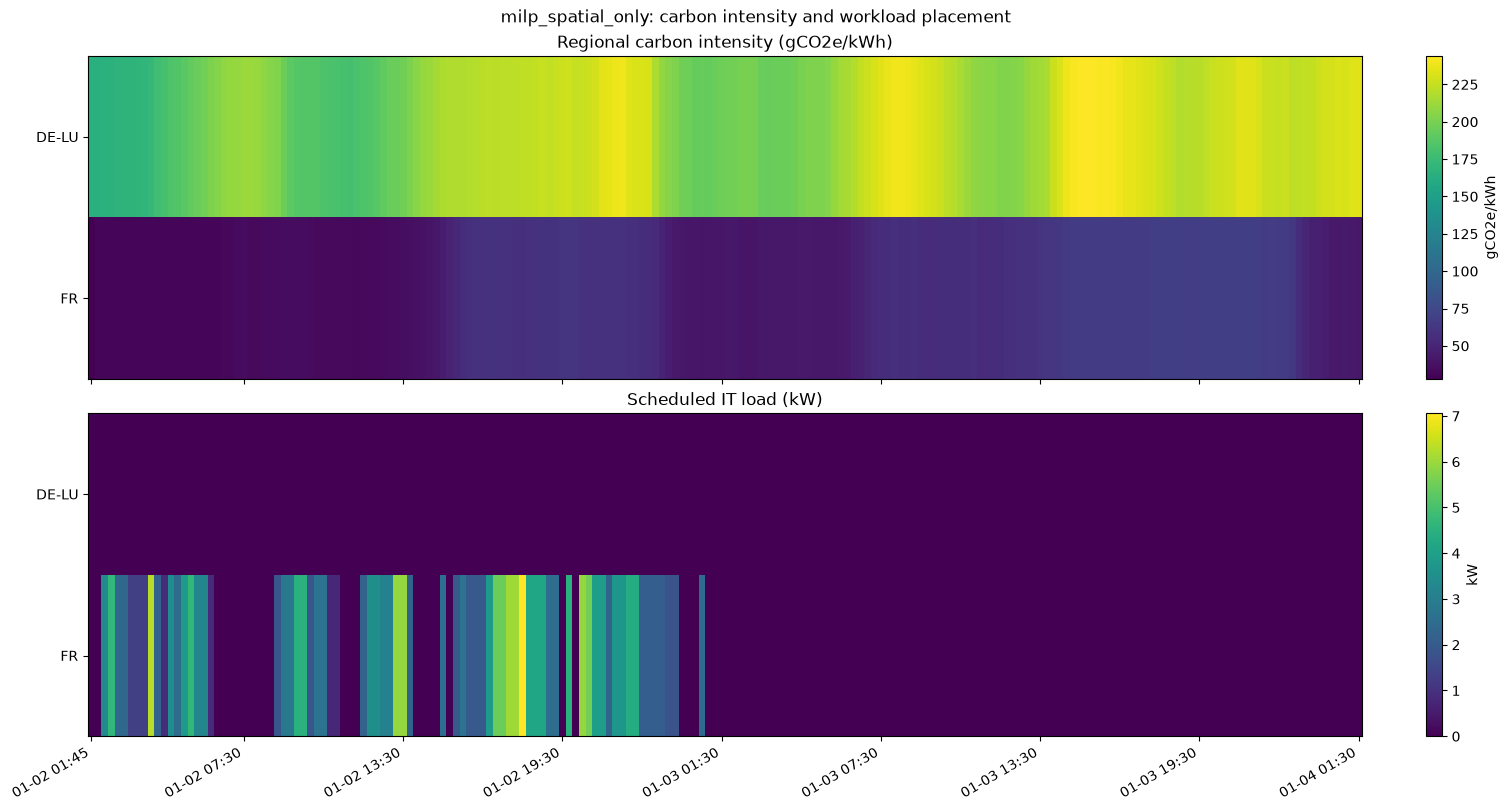

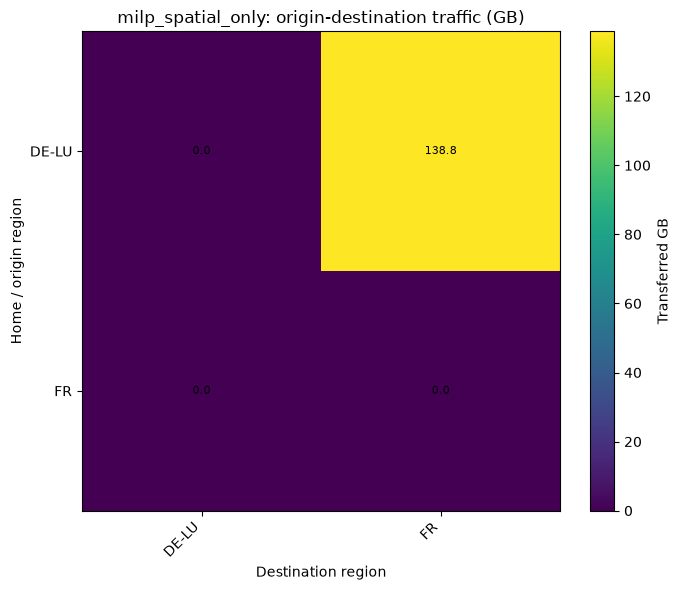

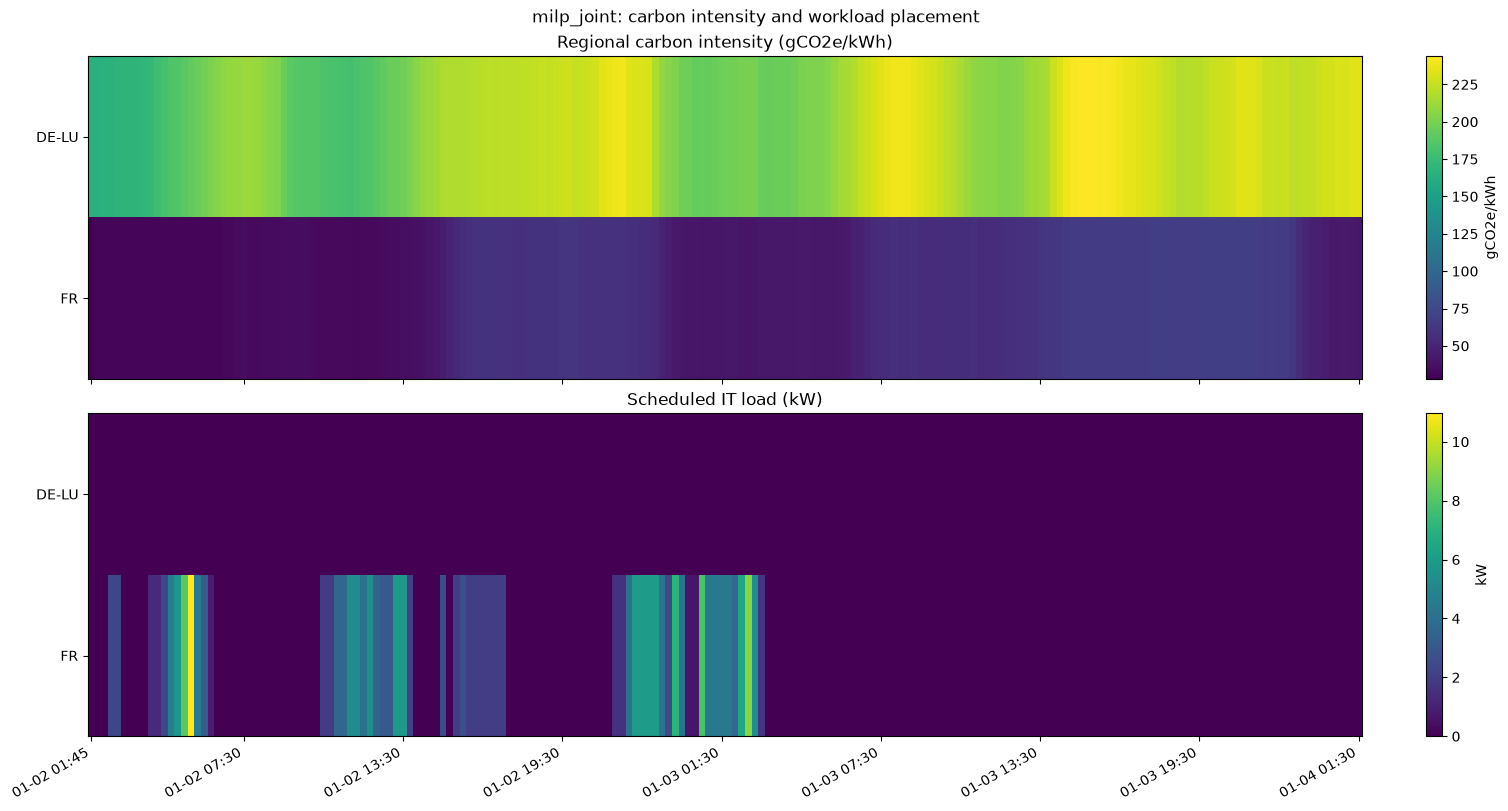

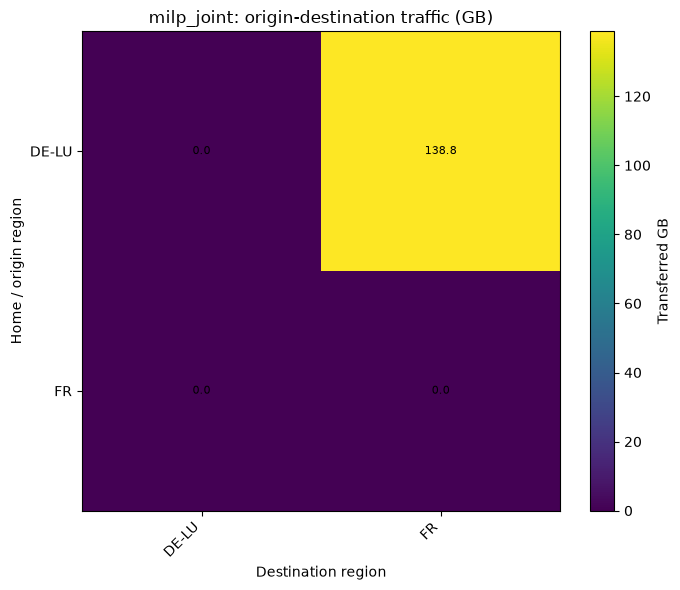

In [20]:
def plot_ci_and_placement(carbon: pd.DataFrame, load_kw: pd.DataFrame, title: str = "Carbon intensity and workload placement"):
    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
    ci_values = carbon.T.to_numpy(dtype=float)
    load_values = load_kw.loc[carbon.columns, carbon.index].to_numpy(dtype=float)

    im0 = axes[0].imshow(ci_values, aspect="auto", interpolation="nearest")
    axes[0].set_yticks(range(len(carbon.columns)), carbon.columns)
    axes[0].set_title("Regional carbon intensity (gCO2e/kWh)")
    fig.colorbar(im0, ax=axes[0], label="gCO2e/kWh")

    im1 = axes[1].imshow(load_values, aspect="auto", interpolation="nearest")
    axes[1].set_yticks(range(len(carbon.columns)), carbon.columns)
    axes[1].set_title("Scheduled IT load (kW)")
    fig.colorbar(im1, ax=axes[1], label="kW")

    n = len(carbon.index)
    ticks = np.linspace(0, n - 1, min(9, n), dtype=int)
    axes[1].set_xticks(ticks, [carbon.index[i].strftime("%m-%d %H:%M") for i in ticks], rotation=30, ha="right")
    fig.suptitle(title)
    plt.show()


def plot_migration_flow(schedule: pd.DataFrame, region_names: list[str], title: str = "Migration flows (GB)"):
    if schedule.empty:
        print("No assigned jobs to plot.")
        return
    flows = schedule[schedule["migrated"]].groupby(["home_region", "execution_region"])["transfer_gb"].sum().unstack(fill_value=0)
    flows = flows.reindex(index=region_names, columns=region_names, fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(flows.to_numpy(), aspect="auto")
    ax.set_xticks(range(len(region_names)), region_names, rotation=45, ha="right")
    ax.set_yticks(range(len(region_names)), region_names)
    ax.set_xlabel("Destination region")
    ax.set_ylabel("Home / origin region")
    ax.set_title(title)
    for i in range(len(region_names)):
        for j in range(len(region_names)):
            ax.text(j, i, f"{flows.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="Transferred GB")
    fig.tight_layout()
    plt.show()
    return flows


if policy_results:
    for policy_name in ["milp_spatial_only", "milp_joint"]:
        if policy_name in policy_results:
            plot_ci_and_placement(
                carbon_window,
                policy_results[policy_name]["load_kw"],
                title=f"{policy_name}: carbon intensity and workload placement",
            )
            flow_matrix = plot_migration_flow(
                policy_results[policy_name]["schedule"], regions,
                title=f"{policy_name}: origin-destination traffic (GB)",
            )


## 11. Network-energy sensitivity analysis

A spatial decision should not be judged using an arbitrary network-energy coefficient. Re-solve the MILP across several multipliers of the baseline \(\eta_{or}\) matrix. If migration collapses as the network coefficient increases, report the break-even range and the assumed network-energy model.

,network_energy_multiplier,total_emissions_g,network_emissions_g,migrated_jobs,transferred_gb,solver_status
0,0.0,2285.972,0.000,19,138.799,0
1,0.5,2365.828,79.809,19,138.799,0
2,1.0,2445.347,158.555,19,138.799,0
3,2.0,2603.415,315.910,19,138.799,0
4,4.0,2919.168,631.350,19,138.799,0


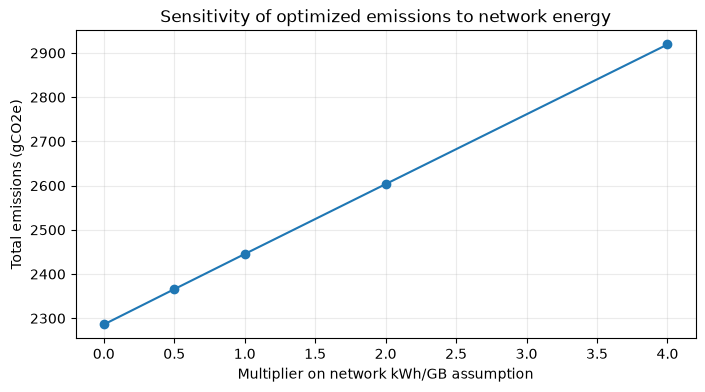

In [21]:
if carbon_window is not None and len(regions) >= 2:
    sensitivity_rows = []
    for multiplier in [0.0, 0.5, 1.0, 2.0, 4.0]:
        eta_sensitivity = network_kwh_per_gb * multiplier
        try:
            solved = solve_spatial_milp(
                jobs, carbon_window, capacity_kw, eta_sensitivity,
                bandwidth_gb_per_slot, allow_spatial=True, allow_temporal=True,
            )
            evaluated = evaluate_schedule(
                solved["assignments"], jobs, carbon_window, capacity_kw,
                eta_sensitivity, bandwidth_gb_per_slot,
            )
            m = evaluated["metrics"]
            sensitivity_rows.append({
                "network_energy_multiplier": multiplier,
                "total_emissions_g": m["total_emissions_g"],
                "network_emissions_g": m["network_emissions_g"],
                "migrated_jobs": m["migrated_jobs"],
                "transferred_gb": m["total_transfer_gb"],
                "solver_status": solved["status"],
            })
        except RuntimeError as exc:
            print(f"Sensitivity multiplier {multiplier} failed: {exc}")
    sensitivity_table = pd.DataFrame(sensitivity_rows)
    display(sensitivity_table.round(3))
    if not sensitivity_table.empty:
        ax = sensitivity_table.plot(
            x="network_energy_multiplier", y="total_emissions_g",
            marker="o", figsize=(8, 4), legend=False,
        )
        ax.set_xlabel("Multiplier on network kWh/GB assumption")
        ax.set_ylabel("Total emissions (gCO2e)")
        ax.set_title("Sensitivity of optimized emissions to network energy")
        ax.grid(alpha=0.25)
        plt.show()


## 12. Rolling-horizon operation: day-ahead versus real-time

The deterministic MILP above uses a known carbon-intensity series for the entire horizon. In deployment, replace future observations with forecasts:

- **Day-ahead:** forecast regional CI and workload arrivals for (for example) the next 24 hours; solve the MILP; commit only near-term decisions; re-optimize as forecasts update.
- **Real-time / receding horizon:** at each control interval, update current CI, available capacity, queue state and link availability. Keep already-running jobs fixed, then use the greedy heuristic or a short-horizon MILP for eligible jobs.
- **Forecast uncertainty:** evaluate multiple CI scenarios or penalize high-uncertainty destinations. A conservative linear approximation uses `forecast_CI + z * forecast_sigma`; a more rigorous model uses scenario-based stochastic optimization or CVaR.
- **Migration eligibility:** only migrate checkpointable/stateless workloads, and include state size, transfer latency, data residency, inter-region latency, and migration interruption in the job eligibility/cost model.

A research evaluation should compare perfect-foresight scheduling (the deterministic MILP using realized CI; an upper bound), day-ahead forecast scheduling, and rolling-horizon scheduling with the same workload and infrastructure constraints.

## 13. Export experimental outputs

The following cell exports the KPI comparison, job-level schedule and workload-allocation matrix. These files can be used to construct tables and figures for the thesis.

In [22]:
#if policy_results:
#    output_dir = Path("spatial_shifting_outputs")
#    output_dir.mkdir(exist_ok=True)
#
#    kpi_table.to_csv(output_dir / "policy_kpis.csv")
#    for policy_name, result in policy_results.items():
#        result["schedule"].to_csv(output_dir / f"schedule_{policy_name}.csv", index=False)
#        result["load_kw"].T.to_csv(output_dir / f"workload_allocation_kw_{policy_name}.csv")
#
#    if "sensitivity_table" in globals() and not sensitivity_table.empty:
#        sensitivity_table.to_csv(output_dir / "network_sensitivity.csv", index=False)
#
#    print("Outputs saved to:", output_dir.resolve())
#else:
#    print("No optimization outputs to export yet. Add at least two valid regional datasets.")
#

Outputs saved to: C:\University25\master\_teza_master\soft\project\spatial_shifting_outputs


## 14. Interpretation checklist for the research report

Before making a carbon-saving claim, verify the following:

1. All regions cover the same UTC slots and use a consistent CI definition and lifecycle boundary.
2. The regional signal is clearly described as average generation-based, consumption-based or marginal; do not mix these concepts.
3. The workload profile (power, duration, arrivals, deadlines, transfer volume) is measured or justified as a scenario.
4. Capacity is modeled in consistent units and is region/time-specific where possible.
5. Network kWh/GB, route topology, bandwidth, data volume and transfer timing are calibrated or subjected to sensitivity analysis.
6. The comparison includes local-immediate, local-only temporal, spatial-only and joint spatio-temporal policies.
7. MILP feasibility, optimality gap/time limit, SLA violations and capacity/bandwidth violations are reported.
8. Results are repeated across different days/seasons and workload seeds; report mean and dispersion, not one favorable day.
9. The perfect-foresight MILP is labeled an oracle/upper bound when it uses realized future CI.
10. If using forecasts, measure forecast error and report the impact on realized emissions after rolling-horizon execution.